# Cancelamento de reservas de hotel: análise exploratória

**Pergunta:** quais reservas têm mais chance de ser canceladas, no momento em que entram?

**Para quê:** decidir em quais reservas pedir depósito ou ligar para confirmar, e quantos cancelamentos esperar para calibrar o overbooking.

**Este notebook** decide quais variáveis entram no modelo e de que forma. O modelo e a avaliação ficam em `02_modelo.ipynb`.

## Resumo

*(preenchido ao final da análise)*

- Taxa de cancelamento: __.
- Variáveis excluídas por vazamento: __.
- Escopo do modelo: __.
- Variáveis que entram, e de que forma: __.

## Contexto e abordagem

**Contexto.** Dois hotéis em Portugal, um urbano (City Hotel, em Lisboa) e um resort (Resort Hotel, no Algarve), com chegadas de julho de 2015 a agosto de 2017. Cada linha é uma reserva. Uma reserva cancelada (ou um no-show) pode virar quarto vazio: a diária não entra e muitas vezes não dá tempo de revender o quarto. Fonte: Antonio, Almeida e Nunes (2019), *Hotel booking demand datasets*, Data in Brief.

**Abordagem.** Regressão logística: o resultado é sim ou não (cancelou ou veio), e o negócio precisa de uma probabilidade de cancelamento por reserva para decidir onde agir.

**Premissa que guia a análise.** O modelo será usado **no momento em que a reserva entra**. Então só pode usar o que o hotel sabe nessa hora. Uma variável que só existe, ou só tem aquele valor, depois do check-in ou do cancelamento é **vazamento**: deixa o modelo ótimo no papel e inútil na prática.

**Validação.** Pela mesma premissa, o modelo é avaliado em reservas futuras: treino com as chegadas de 2015 e 2016, teste com as de 2017.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes_logistica import (CORES, aplicar_estilo, resumo_colunas,
                               taxa_por_nivel, grafico_taxa_por_nivel, contar_casos,
                               logito_por_faixa, grafico_logito, v_cramer)

aplicar_estilo()
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

## 1. A base

In [2]:
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
print('Linhas e colunas:', hotel.shape)
hotel.head()

Linhas e colunas: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
resumo_colunas(hotel)

,tipo,n_niveis,missing,pct_missing,mais_frequentes
hotel,str,2,0,0.000000,City Hotel (79.330) | Resort Hotel (40.060)
is_canceled,int64,2,0,0.000000,0 (75.166) | 1 (44.224)
lead_time,int64,479,0,0.000000,0 (6.345) | 1 (3.460) | 2 (2.069)
arrival_date_year,int64,3,0,0.000000,2016 (56.707) | 2017 (40.687) | 2015 (21.996)
arrival_date_month,str,12,0,0.000000,August (13.877) | July (12.661) | May (11.791)
arrival_date_week_number,int64,53,0,0.000000,33 (3.580) | 30 (3.087) | 32 (3.045)
arrival_date_day_of_month,int64,31,0,0.000000,17 (4.406) | 5 (4.317) | 15 (4.196)
stays_in_weekend_nights,int64,17,0,0.000000,0 (51.998) | 2 (33.308) | 1 (30.626)
stays_in_week_nights,int64,35,0,0.000000,2 (33.684) | 1 (30.310) | 3 (22.258)
adults,int64,14,0,0.000000,2 (89.680) | 1 (23.027) | 3 (6.202)


**Leitura.**

- **119.390 reservas e 32 colunas.** O `y` (`is_canceled`) já vem como 0/1: 44.224 canceladas (37,0%), contando os no-shows.
- **O tipo no Python nem sempre é o tipo da variável:**
  - `is_repeated_guest` é número, mas binária;
  - `agent` e `company` são decimais só porque têm missing: são códigos, ou seja, categóricas;
  - ano, semana e dia da chegada são números, mas são calendário.
- **Missing:** `company` (94,3%), `agent` (13,7%), `country` (488 reservas) e `children` (4 reservas).
- **Primeiros sinais para investigar:**
  - `reservation_status`: 43.017 Canceled + 1.207 No-Show = 44.224, exatamente as reservas canceladas. É o próprio `y` escrito de outro jeito: se entrasse no modelo, ele acertaria tudo no papel e não serviria para nada na prática. Sai (confirmar na seção de vazamento).
  - `deposit_type`: 88% das reservas são sem depósito (104.641), 12% Non Refund (14.587) e só 162 Refundable. A ação em discussão (pedir depósito ou ligar para confirmar) só faz sentido para quem ainda não deu garantia: candidato a definir o **escopo** do modelo, e não a entrar como variável. As 162 Refundable são poucas demais para estimar qualquer efeito.
  - `babies`: 0 em 99% das reservas (118.473). Uma variável quase constante separa pouco quem cancela de quem vem. Candidata a sair, ou a ser juntada com `children` ("tem criança ou bebê").
  - `distribution_channel`: 82% das reservas chegam por agências de viagem ou operadoras de turismo (TA/TO, *travel agents / tour operators*). O `market_segment` já separa esse grupo em agência online (Online TA) e agência ou operadora tradicional (Offline TA/TO), então o canal provavelmente repete o segmento com menos detalhe. Candidata a sair por redundância (confirmar com o V de Cramér entre os dois).

## 2. Dicionário de dados, primeira versão

O que cada variável é e o que esperamos dela **antes de olhar a relação com o cancelamento**. A coluna **Quando se sabe** aplica a premissa do momento da decisão:

- **na reserva:** o hotel tem a informação quando a reserva entra;
- **pode mudar até a chegada:** existe na reserva, mas a base guarda o valor do fim;
- **só no fim:** só existe depois do check-in ou do cancelamento (vazamento);
- **?:** não sabemos, e os dados vão mostrar.

| Variável | Descrição | Tipo | Quando se sabe | Pergunta a responder |
| :--- | :--- | :--- | :--- | :--- |
| **Hotel e antecedência** | | | | |
| `hotel` | City Hotel (Lisboa) ou Resort Hotel (Algarve) | categórica (2) | na reserva | O urbano cancela mais que o resort? |
| `lead_time` | Dias entre a reserva e a chegada | numérica | na reserva | Mais antecedência, mais chance de mudar de plano? A relação com o logito é linear? |
| **Data da chegada** | | | | |
| `arrival_date_year` | Ano da chegada | calendário (3) | na reserva | Não serve como variável: reserva futura sempre tem ano novo. Separa treino e teste. |
| `arrival_date_month` | Mês da chegada | categórica (12) | na reserva | Há sazonalidade? Dá para agrupar em temporadas? |
| `arrival_date_week_number` | Semana do ano da chegada | calendário (53) | na reserva | Acrescenta algo ao mês? |
| `arrival_date_day_of_month` | Dia do mês da chegada | calendário (31) | na reserva | Tem alguma lógica de negócio? |
| **Estadia e hóspedes** | | | | |
| `stays_in_weekend_nights` | Noites de sábado ou domingo | contagem | pode mudar até a chegada | Lazer (fim de semana) × trabalho (semana)? |
| `stays_in_week_nights` | Noites de segunda a sexta | contagem | pode mudar até a chegada | Vale somar com as noites de fim de semana? |
| `adults` | Adultos | contagem | na reserva | Reserva sem adulto é erro de cadastro? |
| `children` | Crianças | contagem | na reserva | Família cancela mais? |
| `babies` | Bebês | contagem | na reserva | Quase sempre zero: ajuda em algo? |
| `meal` | Regime: BB, HB, FB, SC, Undefined | categórica (5) | na reserva | Pela documentação, Undefined e SC são a mesma coisa (sem refeição). Os dados confirmam? |
| **Origem e canal** | | | | |
| `country` | País do hóspede | categórica (177) | ? | Pode ser preenchido só no check-in. Se for, é vazamento. |
| `market_segment` | Segmento: Online TA (agências online, como Booking.com), Offline TA/TO (agências tradicionais e operadoras, que costumam reservar blocos de quartos), Groups, Direct, Corporate... | categórica (8) | na reserva | Grupos e operadoras se comportam diferente? Algum nível tem poucas reservas? |
| `distribution_channel` | Canal: TA/TO (agências de viagem e operadoras de turismo), Direct, Corporate, GDS (sistemas de reserva usados por agências) | categórica (5) | na reserva | Repete o segmento? |
| `agent` | Código da agência | código (333) | na reserva | Centenas de códigos sem significado para o público. |
| `company` | Código da empresa que paga | código (352) | na reserva | 94% vazia: ajuda em algo? |
| `customer_type` | Transient, Transient-Party, Contract, Group | categórica (4) | na reserva | Cliente avulso cancela mais que contrato e grupo? |
| **Histórico do cliente** | | | | |
| `is_repeated_guest` | Já se hospedou antes | binária | na reserva | Quem volta cancela menos? |
| `previous_cancellations` | Reservas anteriores canceladas pelo cliente | contagem | na reserva | Quem já cancelou cancela de novo? |
| `previous_bookings_not_canceled` | Reservas anteriores que o cliente manteve | contagem | na reserva | Repete o `is_repeated_guest`? |
| **Quarto, pedidos e pagamento** | | | | |
| `reserved_room_type` | Tipo de quarto reservado (código anônimo) | categórica (10) | na reserva | O código não significa nada para o público. |
| `assigned_room_type` | Tipo de quarto entregue | categórica (12) | só no fim | Definido no check-in: quem cancelou nunca recebeu quarto. |
| `booking_changes` | Alterações até o check-in ou o cancelamento | contagem | só no fim | No momento da reserva, é sempre zero. |
| `deposit_type` | No Deposit, Non Refund (pago, sem reembolso), Refundable | categórica (3) | na reserva | Quem pagou sem reembolso cancela menos? A ação em discussão (pedir depósito) só vale para quem ainda não deu garantia. |
| `days_in_waiting_list` | Dias em lista de espera até a confirmação | numérica | na reserva | Esperar muito leva a desistir? |
| `adr` | Diária média | numérica | na reserva | Há diárias negativas ou zeradas? Diária alta, mais cancelamento? |
| `required_car_parking_spaces` | Vagas de garagem pedidas | contagem | ? | Pode ser pedida só na chegada. Se for, é vazamento. |
| `total_of_special_requests` | Pedidos especiais (cama de casal, andar alto...) | contagem | pode mudar até a chegada | Quem faz pedido pretende vir? |
| **Status da reserva** | | | | |
| `reservation_status` | Check-Out, Canceled, No-Show | categórica (3) | só no fim | É o próprio `y` escrito de outro jeito. |
| `reservation_status_date` | Data do último status | data | só no fim | Para quem cancelou, é a data do cancelamento. |
| **Variável resposta** | | | | |
| `is_canceled` | 1 = cancelada (inclui no-show), 0 = o hóspede veio | binária | | Qual a taxa de cancelamento? |

## 3. O cancelamento (o `y`)

**Perguntas:** quanto se cancela? O evento é raro? A taxa é estável no tempo?

A última importa por causa da validação: o modelo aprende com as chegadas de 2015 e 2016 e é testado nas de 2017. Se a taxa mudar entre os dois períodos, as probabilidades previstas para 2017 podem sair deslocadas.

Nesta seção a base é a inteira. O escopo do modelo é decidido na seção 5.

In [4]:
taxa_geral = hotel['is_canceled'].mean()

contagem = hotel['is_canceled'].value_counts().sort_index()
display(pd.DataFrame({'reservas': contagem, 'pct': contagem / contagem.sum()})
          .rename(index={0: 'veio (0)', 1: 'cancelou (1)'}))

# o status final só serve para descrever o y: Canceled e No-Show caem todos em y = 1
pd.crosstab(hotel['reservation_status'], hotel['is_canceled'], margins=True, margins_name='total')


,reservas,pct
is_canceled,,
veio (0),75166,0.629584
cancelou (1),44224,0.370416


is_canceled,0,1,total
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
total,75166,44224,119390


In [5]:
taxa_por_nivel(hotel, 'hotel')

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
hotel,,,,,,,
City Hotel,79330,0.664461,33102,0.417270,0.413842,0.420705,-0.333988
Resort Hotel,40060,0.335539,11122,0.277634,0.273270,0.282040,-0.956203


**Leitura.**

- **44.224 das 119.390 reservas foram canceladas (37,0%).** Pelo status final, 43.017 avisaram o cancelamento e 1.207 não apareceram (no-show). As duas situações ficam juntas no `y`: para o hotel, as duas viram quarto vazio. O no-show é o caso mais caro, porque não deixa tempo para revender o quarto.
- **Não é um evento raro.** Com 37% de cancelamento, não é preciso balancear a base nem usar técnica de evento raro.
- **A taxa geral é a referência.** Sem modelo, a melhor estimativa para qualquer reserva é 37%. O modelo só tem valor se separar reservas bem mais arriscadas de reservas bem mais seguras do que isso.
- **O hotel urbano cancela mais:** 41,7% (IC 95% de 41,4% a 42,1%) contra 27,8% no resort, e tem dois terços das reservas. A diferença é o primeiro corte de negócio, e o modelo precisa considerá-la.

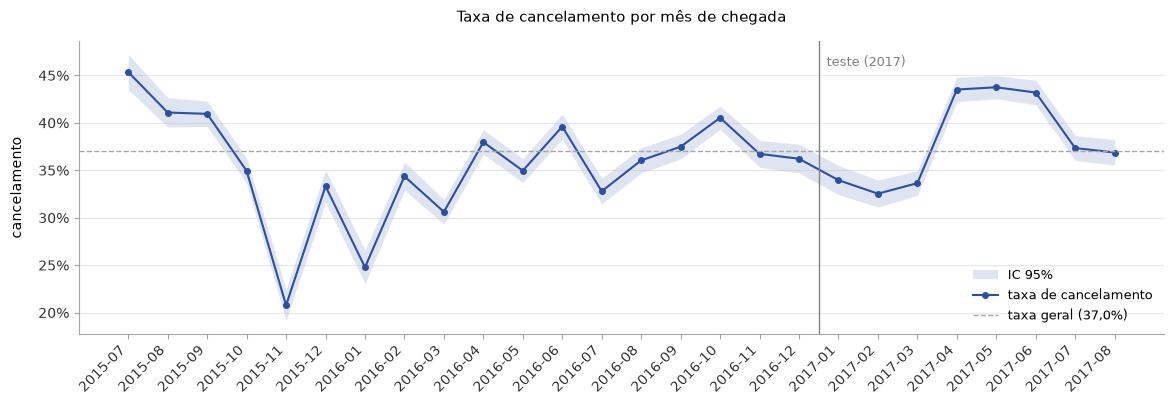

,n,taxa,ic_inf,ic_sup
mes_chegada,,,,
2015-07,2776,0.453530,0.435088,0.472101
2015-08,3889,0.410903,0.395535,0.426446
2015-09,5114,0.409464,0.396060,0.423004
2015-10,4957,0.349405,0.336253,0.362790
2015-11,2340,0.207692,0.191742,0.224601
2015-12,2920,0.333219,0.316351,0.350525
2016-01,2248,0.247776,0.230370,0.266043
2016-02,3891,0.343613,0.328852,0.358683
2016-03,4824,0.306177,0.293330,0.319334


In [6]:
# mês de chegada como período (ano-mês), para os meses saírem em ordem no tempo
hotel['mes_chegada'] = pd.to_datetime(
    hotel['arrival_date_year'].astype(str) + '-' + hotel['arrival_date_month'], format='%Y-%B'
).dt.to_period('M')

por_mes = taxa_por_nivel(hotel, 'mes_chegada')
ax = grafico_taxa_por_nivel(por_mes, taxa_geral=taxa_geral, linha=True,
                            titulo='Taxa de cancelamento por mês de chegada')
inicio_teste = list(por_mes.index).index(pd.Period('2017-01', 'M'))
ax.axvline(inicio_teste - 0.5, color='gray', linewidth=1)
ax.text(inicio_teste - 0.3, ax.get_ylim()[1] * 0.97, 'teste (2017)', fontsize=9, va='top', color='gray')
plt.show()

por_mes[['n', 'taxa', 'ic_inf', 'ic_sup']]


In [7]:
periodos = ['treino: 2015–2016', 'teste: 2017 (jan–ago)']
hotel['periodo'] = pd.Categorical(
    np.where(hotel['arrival_date_year'] == 2017, periodos[1], periodos[0]), categories=periodos
)
display(taxa_por_nivel(hotel, 'periodo'))

# os mesmos meses (janeiro a agosto) em 2016 e 2017, para separar a alta do efeito da época do ano
jan_a_ago = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
mesmos_meses = hotel[hotel['arrival_date_month'].isin(jan_a_ago) & hotel['arrival_date_year'].isin([2016, 2017])]
taxa_por_nivel(mesmos_meses, 'arrival_date_year')

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
periodo,,,,,,,
treino: 2015–2016,78703,0.659209,28479,0.361854,0.358504,0.365218,-0.567318
teste: 2017 (jan–ago),40687,0.340791,15745,0.386979,0.382257,0.391722,-0.460019


,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
arrival_date_year,,,,,,,
2016,36796,0.474891,12767,0.346967,0.342120,0.351846,-0.632379
2017,40687,0.525109,15745,0.386979,0.382257,0.391722,-0.460019


**Leitura.**

- **A taxa oscila bastante de um mês para outro:** 45,4% em julho de 2015 (o primeiro mês da base), 20,8% em novembro de 2015 e perto de 44% de abril a junho de 2017. Com milhares de reservas por mês, os intervalos de confiança têm cerca de 1 ponto para cada lado: as oscilações não são acaso.
- **2017 cancela mais que o período de treino:** 38,7% contra 36,2%. Comparando os mesmos meses (janeiro a agosto), 2016 teve 34,7% e 2017, 38,7%: a alta de 4 pontos não é só efeito da época do ano.
- **O que isso muda:**
  - para **ordenar** as reservas (em quais agir primeiro), a alta geral atrapalha pouco: o que importa é o modelo colocar as reservas certas no topo;
  - para **estimar** quantos cancelamentos esperar (overbooking), as probabilidades aprendidas em 2015–2016 tendem a sair baixas para 2017. A calibração no teste precisa ser conferida;
  - no anexo técnico, a mudança entra como limitação.
- **A conferir na seção 5:** se a alta muda de tamanho dentro do escopo do modelo.

## 4. Qualidade dos dados

**Perguntas:** onde há vazios, e eles são erro ou "não se aplica"? Há linhas repetidas? Há valores impossíveis ou suspeitos?

Aqui a base inteira é usada: são problemas do próprio dado, e a limpeza decidida vale igual para treino e teste.

### 4.1 Vazios

In [8]:
display(resumo_colunas(hotel).query('missing > 0')[['missing', 'pct_missing']])

# agent e company vazios: falta de dado ou reserva sem agência / sem empresa pagando?
hotel.groupby('market_segment').agg(
    reservas=('is_canceled', 'size'),
    pct_sem_agent=('agent', lambda s: s.isna().mean()),
    pct_sem_company=('company', lambda s: s.isna().mean()),
).sort_values('reservas', ascending=False)

,missing,pct_missing
children,4,0.000034
country,488,0.004087
agent,16340,0.136862
company,112593,0.943069


,reservas,pct_sem_agent,pct_sem_company
market_segment,,,
Online TA,56477,0.006162,0.998300
Offline TA/TO,24219,0.016062,0.995623
Groups,19811,0.209379,0.929786
Direct,12606,0.476519,0.983500
Corporate,5295,0.867611,0.155619
Complementary,743,0.861373,0.578735
Aviation,237,0.894515,0.105485
Undefined,2,1.000000,1.000000


In [9]:
# as 4 reservas sem children: dá para preencher com 0 ou são cadastros incompletos?
hotel.loc[hotel['children'].isna(),
          ['hotel', 'adults', 'children', 'babies', 'market_segment', 'distribution_channel', 'is_canceled']]

,hotel,adults,children,babies,market_segment,distribution_channel,is_canceled
40600,City Hotel,2,NaN,0,Undefined,Undefined,1
40667,City Hotel,2,NaN,0,Direct,Undefined,1
40679,City Hotel,3,NaN,0,Undefined,Undefined,1
41160,City Hotel,2,NaN,0,Online TA,Undefined,1


**Leitura.**

- **Só 4 colunas têm vazios, e a maioria significa "não se aplica", não falta de dado:**
  - `agent` (16.340, 13,7%): quase não falta nas reservas por agência (0,6% na agência online e 1,6% na operadora tradicional) e falta em boa parte das reservas diretas (48%), corporativas (87%), de tripulação (89%) e de cortesia (86%). Vazio quer dizer **"sem agência"**;
  - `company` (112.593, 94,3%): só é preenchido quando uma empresa paga a reserva, o que acontece sobretudo nos segmentos corporativo (84% preenchido) e de tripulação de companhias aéreas (89%). Vazio quer dizer **"não é pago por empresa"**;
  - `country` (488): falta de dado de fato. Pesa pouco, e a variável é suspeita de vazamento (seção 5);
  - `children` (4): quatro reservas do hotel urbano, todas canceladas. Têm adultos e nenhum bebê, mas o cadastro está incompleto em outros campos também: as quatro têm `distribution_channel = Undefined` (4 das 5 reservas com canal indefinido) e duas têm `market_segment = Undefined` (as 2 únicas da base). Proposta: **remover**, como cadastros incompletos.
- **Consequência:** se `agent` ou `company` entrarem no modelo, o vazio vira uma categoria própria, e não uma linha descartada. Pelo dicionário, as duas tendem a sair (códigos sem significado para o público e coluna quase toda vazia).

### 4.2 Linhas repetidas

In [10]:
copia = hotel.duplicated()                  # repete uma linha que já apareceu antes
tem_gemea = hotel.duplicated(keep=False)    # tem pelo menos uma linha idêntica na base
print('Cópias a mais:', copia.sum(), f'({copia.mean():.1%} da base)')
print('Linhas com pelo menos uma gêmea:', tem_gemea.sum())

display(taxa_por_nivel(hotel.assign(tem_gemea=tem_gemea), 'tem_gemea'))
(hotel.assign(tem_gemea=tem_gemea)
      .groupby('market_segment')['tem_gemea'].agg(reservas='size', pct_com_gemea='mean')
      .sort_values('reservas', ascending=False))

Cópias a mais: 31994 (26.8% da base)
Linhas com pelo menos uma gêmea: 40165


,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
tem_gemea,,,,,,,
False,79225,0.663582,20773,0.262203,0.259151,0.265277,-1.034536
True,40165,0.336418,23451,0.583867,0.579038,0.588679,0.338658


,reservas,pct_com_gemea
market_segment,,
Online TA,56477,0.146414
Offline TA/TO,24219,0.504150
Groups,19811,0.843622
Direct,12606,0.111455
Corporate,5295,0.278376
Complementary,743,0.100942
Aviation,237,0.080169
Undefined,2,0.000000


**Leitura.**

- **31.994 linhas são cópia idêntica de outra (26,8% da base)**, e 40.165 têm pelo menos uma gêmea.
- **As cópias não são aleatórias:** 84% das reservas de grupo e 50% das de operadora tradicional têm gêmea, contra 15% na agência online. E as linhas com gêmea cancelam muito mais: 58,4%, contra 26,2%.

**Erro ou vários quartos de uma mesma reserva?** A base não tem número de reserva, então não dá para provar. Dá para juntar evidências: se forem quartos de uma mesma reserva, as cópias devem formar conjuntos de tamanho plausível e se concentrar onde se reserva em bloco (grupos e operadoras).

In [11]:
# cada conjunto = linhas idênticas em todas as colunas
conjuntos = (hotel.groupby(list(hotel.columns), dropna=False).size()
                  .rename('linhas').reset_index())
conjuntos = conjuntos[conjuntos['linhas'] > 1]
print('Conjuntos de linhas idênticas:', len(conjuntos))

tamanho = pd.cut(conjuntos['linhas'], [1, 2, 5, 10, 20, 50, np.inf],
                 labels=['2', '3 a 5', '6 a 10', '11 a 20', '21 a 50', 'mais de 50'])
display(tamanho.value_counts().sort_index().to_frame('conjuntos'))

display(conjuntos.groupby('market_segment')['linhas']
                 .agg(conjuntos='size', mediana='median', maximo='max')
                 .sort_values('conjuntos', ascending=False))

conjuntos.nlargest(3, 'linhas')[['hotel', 'linhas', 'market_segment', 'lead_time', 'arrival_date_year',
                                 'arrival_date_month', 'arrival_date_day_of_month', 'adr', 'is_canceled']]

Conjuntos de linhas idênticas: 8171


,conjuntos
linhas,
2,5034
3 a 5,1741
6 a 10,605
11 a 20,468
21 a 50,274
mais de 50,49


,conjuntos,mediana,maximo
market_segment,,,
Online TA,3410,2.0,15
Offline TA/TO,1880,2.0,109
Groups,1844,4.0,180
Direct,603,2.0,11
Corporate,391,2.0,99
Complementary,34,2.0,4
Aviation,9,2.0,3


,hotel,linhas,market_segment,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,adr,is_canceled
52542,City Hotel,180,Groups,277,2016,November,7,100.0,1
44843,City Hotel,150,Groups,68,2016,February,17,75.0,1
50863,City Hotel,109,Offline TA/TO,188,2016,June,15,130.0,1


In [12]:
# na agência online, as linhas com gêmea parecem registros "vazios" ou se comportam diferente?
online = hotel[hotel['market_segment'] == 'Online TA'].assign(tem_gemea=tem_gemea)
online.groupby('tem_gemea').agg(
    reservas=('is_canceled', 'size'),
    taxa=('is_canceled', 'mean'),
    pct_sem_pedido_especial=('total_of_special_requests', lambda s: (s == 0).mean()),
    antecedencia_mediana=('lead_time', 'median'),
)

,reservas,taxa,pct_sem_pedido_especial,antecedencia_mediana
tem_gemea,,,,
False,48208,0.345378,0.359442,53.0
True,8269,0.494498,0.411295,97.0


**Leitura.**

- **São 8.171 conjuntos de linhas idênticas.** Mais da metade (5.034) são pares, e só 49 têm mais de 50 linhas.
- **Em grupos e operadoras, o padrão combina com blocos de quartos.** Os conjuntos de grupo têm mediana de 4 linhas. Os três maiores (180, 150 e 109 linhas) são de grupo ou de operadora, no hotel urbano, cada um com a mesma data de chegada em 2016, e foram todos cancelados: o perfil de um bloco reservado com antecedência e devolvido.
- **Na agência online, a explicação é menos clara.** Os conjuntos têm mediana de 2 linhas e chegam a 15. Um par pode ser um casal ou uma família reservando dois quartos; 15 reservas online idênticas (mesmo dia, mesmo preço, mesma antecedência) são difíceis de explicar como pessoas diferentes e podem ser registro duplicado.
- **As linhas com gêmea da agência online não parecem registros "vazios":** a parcela sem pedido especial é parecida com a das outras (41,1% contra 35,9%). Mas elas se comportam diferente: cancelam mais (49,4% contra 34,5%) e são feitas com mais antecedência (mediana de 97 dias contra 53). Parte da diferença no cancelamento pode vir da própria antecedência.
- **Conclusão:** sem número de reserva, não é possível confirmar. A explicação mais provável é a de vários quartos de uma mesma reserva, sobretudo em grupos e operadoras; na agência online, parte pode ser registro duplicado.
- **Consequências:**
  - remover as cópias apagaria quartos que provavelmente existem. A proposta é **manter** e, no modelo, rodar uma versão sem elas: se os fatores principais e a recomendação não mudarem, a dúvida não afeta a decisão;
  - como as cópias são idênticas em tudo, inclusive na data de chegada, gêmeas sempre caem do mesmo lado da divisão treino/teste. A divisão por ano não "vaza" um grupo para o teste;
  - quartos de uma mesma reserva não são independentes, o que deixa os intervalos de confiança do modelo otimistas. Entra como limitação no anexo.

### 4.3 Valores estranhos

In [13]:
hospedes = hotel['adults'] + hotel['children'].fillna(0) + hotel['babies']
noites = hotel['stays_in_weekend_nights'] + hotel['stays_in_week_nights']

casos = {
    'sem hóspede': hospedes == 0,
    'só criança ou bebê, sem adulto': (hotel['adults'] == 0) & (hospedes > 0),
    'zero noites': noites == 0,
    'diária negativa': hotel['adr'] < 0,
    'diária zero': hotel['adr'] == 0,
    'diária acima de 1.000': hotel['adr'] > 1000,
    'antecedência acima de 1 ano': hotel['lead_time'] > 365,
    'meal = Undefined': hotel['meal'] == 'Undefined',
    'market_segment = Undefined': hotel['market_segment'] == 'Undefined',
    'distribution_channel = Undefined': hotel['distribution_channel'] == 'Undefined',
}
contar_casos(hotel, casos)

,n,pct_base,taxa
sem hóspede,180,0.001508,0.138889
"só criança ou bebê, sem adulto",223,0.001868,0.376682
zero noites,715,0.005989,0.048951
diária negativa,1,0.000008,0.000000
diária zero,1959,0.016408,0.108729
diária acima de 1.000,1,0.000008,1.000000
antecedência acima de 1 ano,3148,0.026367,0.676620
meal = Undefined,1169,0.009791,0.244654
market_segment = Undefined,2,0.000017,1.000000
distribution_channel = Undefined,5,0.000042,0.800000


In [14]:
print('Maiores diárias:', hotel['adr'].nlargest(3).tolist(), '| percentil 99:', hotel['adr'].quantile(0.99))
print('Diária negativa:', hotel.loc[hotel['adr'] < 0, 'adr'].tolist())

print('\nDiária zero, por segmento:')
display(hotel.loc[hotel['adr'] == 0, 'market_segment'].value_counts().to_frame('reservas'))

print('Regime de refeição:')
taxa_por_nivel(hotel, 'meal')

Maiores diárias: [5400.0, 510.0, 508.0] | percentil 99: 252.0
Diária negativa: [-6.38]

Diária zero, por segmento:


,reservas
market_segment,
Complementary,680
Online TA,367
Offline TA/TO,332
Groups,252
Direct,240
Corporate,82
Aviation,6


Regime de refeição:


,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
meal,,,,,,,
BB,92310,0.773180,34510,0.373849,0.370733,0.376975,-0.515734
FB,798,0.006684,478,0.598997,0.564597,0.632449,0.400774
HB,14463,0.121141,4984,0.344603,0.336900,0.352389,-0.642798
SC,10650,0.089203,3966,0.372394,0.363260,0.381620,-0.521907
Undefined,1169,0.009791,286,0.244654,0.220873,0.270106,-1.126153


**Leitura.**

- **Impossíveis:**
  - **180 reservas sem nenhum hóspede.** Erro de cadastro. Proposta: **remover**;
  - **uma diária negativa (−6,38) e uma de 5.400**, quando a segunda maior é 510 e o percentil 99 é 252. Erros de digitação. Proposta: **remover as duas**.
- **Suspeitos, mas possíveis:**
  - **223 reservas só com crianças ou bebês, sem adulto.** Pouco provável na prática, mas cancelam como o resto (37,7%) e são poucas. Proposta: manter;
  - **715 reservas com zero noites** (*day use*, uso do quarto durante o dia?). Quase não cancelam (4,9%). Proposta: manter, juntando com as de uma noite quando o total de noites for usado;
  - **1.959 reservas com diária zero.** 680 são cortesia (Complementary), o que faz sentido; as outras se espalham pelos segmentos (pacotes? erro?). Cancelam pouco (10,9%). Proposta: manter;
  - **3.148 reservas feitas com mais de um ano de antecedência**, com 67,7% de cancelamento. Não é erro: combina com blocos de quartos reservados por operadoras. A seção 5 olha essas reservas de novo.
- **Vazios disfarçados (`Undefined`):**
  - `meal = Undefined` (1.169): a documentação diz que é o mesmo que SC (sem refeição), mas os dois não se comportam igual (24,5% contra 37,2% de cancelamento). Proposta: **manter separado**, como "não informado";
  - `market_segment = Undefined` (2) e `distribution_channel = Undefined` (5): quase todas são as reservas sem `children` (seção 4.1), que já saem como cadastros incompletos. Sobra uma reserva com canal indefinido. Proposta: juntar em "Outros" se a variável entrar.

### Propostas de limpeza (para o grupo decidir)

| Situação | Reservas | Proposta |
|---|---|---|
| `children` vazio (cadastro incompleto) | 4 | remover |
| `agent` / `company` vazios | 16.340 / 112.593 | categoria "sem agência" / "sem empresa", se a variável entrar |
| Linhas idênticas | 31.994 cópias | manter; conferir o modelo sem elas |
| Sem hóspede | 180 | remover |
| Diária negativa ou de 5.400 | 2 | remover |
| Zero noites | 715 | manter; juntar com 1 noite no total de noites |
| `meal = Undefined` | 1.169 | manter separado ("não informado") |
| `Undefined` no segmento e no canal | 2 e 5 (quase todas entre as 4 acima) | as que sobram vão para "Outros" |

## 5. Vazamento e escopo

**Perguntas:** quais colunas trazem informação de depois da reserva? E em quais reservas o modelo vai ser usado?

O dicionário (seção 2) marcou quatro colunas como **só no fim** e duas como **?**. Aqui os dados confirmam ou derrubam cada suspeita. A base ainda é a inteira.

### 5.1 Vazamento

In [15]:
# data do último status em relação à chegada: antes, no dia ou depois?
chegada = pd.to_datetime(
    hotel['arrival_date_year'].astype(str) + '-' + hotel['arrival_date_month'] + '-'
    + hotel['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
dias_status = (pd.to_datetime(hotel['reservation_status_date']) - chegada).dt.days

momento = pd.cut(dias_status, [-np.inf, -1, 0, np.inf], labels=['antes da chegada', 'no dia', 'depois da chegada']).rename('data do status')
display(pd.crosstab(hotel['reservation_status'], momento, normalize='index').round(3))

# para quem veio, o status muda no check-out: chegada + noites
check_out = hotel['reservation_status'] == 'Check-Out'
print('Check-Out com data = chegada + noites:', f"{(dias_status[check_out] == noites[check_out]).mean():.2%}")

data do status,antes da chegada,no dia,depois da chegada
reservation_status,,,
Canceled,0.980,0.020,0.000
Check-Out,0.000,0.009,0.991
No-Show,0.001,0.999,0.000


Check-Out com data = chegada + noites: 99.96%


In [16]:
# colunas preenchidas ou alteradas depois da reserva: o y já aparece nelas?
casos = {
    'quarto entregue = reservado': hotel['assigned_room_type'] == hotel['reserved_room_type'],
    'quarto entregue diferente do reservado': hotel['assigned_room_type'] != hotel['reserved_room_type'],
    'sem alteração na reserva': hotel['booking_changes'] == 0,
    'com alteração na reserva': hotel['booking_changes'] > 0,
    'sem vaga de garagem': hotel['required_car_parking_spaces'] == 0,
    'com vaga de garagem': hotel['required_car_parking_spaces'] > 0,
}
contar_casos(hotel, casos)

,n,pct_base,taxa
quarto entregue = reservado,104473,0.875057,0.415629
quarto entregue diferente do reservado,14917,0.124943,0.053764
sem alteração na reserva,101314,0.848597,0.408542
com alteração na reserva,18076,0.151403,0.156727
sem vaga de garagem,111974,0.937884,0.394949
com vaga de garagem,7416,0.062116,0.000000


In [17]:
# país: Portugal cancela mais em todos os segmentos, ou só onde o país pode ter sido preenchido no check-in?
hotel['pais'] = np.select([hotel['country'].isna(), hotel['country'] == 'PRT'], ['vazio', 'Portugal'], 'outro')
display(taxa_por_nivel(hotel, 'pais'))

segmentos = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate']
(hotel[hotel['market_segment'].isin(segmentos)]
      .pivot_table(index='market_segment', columns='pais', values='is_canceled', aggfunc='mean')
      .loc[segmentos, ['Portugal', 'outro']].round(3))

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
pais,,,,,,,
Portugal,48590,0.406986,27519,0.566351,0.561940,0.570752,0.266973
outro,70312,0.588927,16638,0.236631,0.233504,0.239787,-1.171219
vazio,488,0.004087,67,0.137295,0.109581,0.170675,-1.831692


pais,Portugal,outro
market_segment,,
Online TA,0.453,0.345
Offline TA/TO,0.678,0.013
Groups,0.840,0.072
Direct,0.206,0.108
Corporate,0.233,0.020


**Leitura.**

- **`reservation_status_date` é a data do desfecho.** 98,0% das canceladas têm a data antes da chegada (o dia do cancelamento), quase todos os no-shows têm a data no próprio dia e 99,1% de quem veio tem a data depois da chegada: em 99,96% dos check-outs, é a chegada mais as noites. Junto com `reservation_status` (seção 3), as duas descrevem o `y`. **Saem.**
- **Três colunas carregam o desfecho:**
  - `assigned_room_type`: quando o quarto entregue é diferente do reservado, só 5,4% cancelam, contra 41,6%. O quarto é definido no check-in, e quem cancela nunca recebe um. **Sai;**
  - `booking_changes`: com alteração, 15,7% cancelam, contra 40,9% sem. Quem fica mais tempo com a reserva ativa tem mais chance de alterá-la, e no momento da reserva a contagem é sempre zero. **Sai;**
  - `required_car_parking_spaces`: nenhuma das 7.416 reservas com vaga foi cancelada. Uma taxa de exatamente 0% em milhares de reservas indica que a vaga é registrada na chegada. **Sai.**
- **`country` é suspeito.** Portugal cancela 56,6%, contra 23,7% dos outros países. Na agência online, a diferença é moderada (45,3% contra 34,5%). Em grupos e operadoras, é extrema: 84,0% contra 7,2% e 67,8% contra 1,3%. Uma explicação provável é o país ser preenchido no check-in, com Portugal como valor padrão de quem nunca chegou. Não dá para provar, mas o risco não compensa. **Sai.**
- **`stays_in_*_nights` e `total_of_special_requests` podem mudar até a chegada.** Não carregam o desfecho como as colunas acima, mas a base guarda o valor final. Ficam como candidatas e voltam na bivariada.

| Variável | Por que sai |
| --- | --- |
| `reservation_status` | É o próprio `y` (Canceled e No-Show = 1) |
| `reservation_status_date` | Data do cancelamento ou do check-out |
| `assigned_room_type` | Definido no check-in |
| `booking_changes` | Acumula até o desfecho; na reserva, é zero |
| `required_car_parking_spaces` | Nenhuma reserva com vaga cancelou: registrada na chegada |
| `country` | Suspeita de preenchimento no check-in |

### 5.2 Escopo

In [18]:
# deposit_type: entra como variável ou define o escopo?
display(taxa_por_nivel(hotel, 'deposit_type'))

hotel.assign(tem_gemea=tem_gemea).groupby('deposit_type').agg(
    reservas=('is_canceled', 'size'),
    antecedencia_mediana=('lead_time', 'median'),
    pct_grupo_ou_operadora=('market_segment', lambda s: s.isin(['Groups', 'Offline TA/TO']).mean()),
    pct_portugal=('pais', lambda s: (s == 'Portugal').mean()),
    pct_com_gemea=('tem_gemea', 'mean'),
)

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
deposit_type,,,,,,,
No Deposit,104641,0.876464,29694,0.283770,0.281047,0.286510,-0.925826
Non Refund,14587,0.122179,14494,0.993624,0.992197,0.994792,5.043563
Refundable,162,0.001357,36,0.222222,0.165057,0.292256,-1.242930


,reservas,antecedencia_mediana,pct_grupo_ou_operadora,pct_portugal,pct_com_gemea
deposit_type,,,,,
No Deposit,104641,56.0,0.284000,0.328418,0.246299
Non Refund,14587,183.0,0.971961,0.971824,0.981422
Refundable,162,169.0,0.827160,0.296296,0.469136


In [19]:
# dentro do escopo proposto (sem depósito): a alta de 2017 continua?
escopo = hotel[hotel['deposit_type'] == 'No Deposit']
display(taxa_por_nivel(escopo, 'periodo'))
taxa_por_nivel(escopo[escopo['arrival_date_month'].isin(jan_a_ago) & escopo['arrival_date_year'].isin([2016, 2017])],
               'arrival_date_year')

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
periodo,,,,,,,
treino: 2015–2016,68107,0.650863,18093,0.265656,0.262352,0.268986,-1.016760
teste: 2017 (jan–ago),36534,0.349137,11601,0.317540,0.312786,0.322332,-0.765078


,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
arrival_date_year,,,,,,,
2016,32317,0.469376,8465,0.261936,0.257171,0.266758,-1.035890
2017,36534,0.530624,11601,0.317540,0.312786,0.322332,-0.765078


**Leitura.**

- **Non Refund cancela 99,4%**, o contrário do esperado: quem pagou sem reembolso deveria vir. E o perfil é outro: antecedência mediana de 183 dias (contra 56 sem depósito), 97,2% de grupos ou operadoras, 97,2% de Portugal e 98,1% de linhas com gêmea. São os blocos de quartos da seção 4.2, quase todos devolvidos.
- **Se `deposit_type` entrasse como variável,** o modelo aprenderia que "pedir depósito leva a cancelar", o oposto da ação em discussão. O efeito vem do tipo de cliente, não do depósito.
- **A decisão só se aplica a quem não deu garantia.** Pedir depósito ou ligar para confirmar não faz sentido para quem já pagou. As 162 Refundable são poucas para estimar qualquer efeito.
- **Proposta: o modelo usa só as reservas sem depósito** (104.641, 28,4% de cancelamento). A frase da apresentação passa a ser "entre as reservas sem garantia de pagamento, 28% são canceladas".
- **A alta de 2017 cresce no escopo.** Treino 26,6%, teste 31,8%. Nos mesmos meses (janeiro a agosto), de 26,2% em 2016 para 31,8% em 2017: 5,6 pontos, contra 4 na base inteira. A calibração no teste fica ainda mais importante.
- **Consequência para o resto do notebook:** as seções 6 e 7 usam o escopo, e as decisões da bivariada saem só do treino (2015 e 2016).

## 6. Univariada

**Perguntas:** como cada candidata se distribui? Há variáveis quase constantes, caudas longas ou categorias pequenas demais para estimar? A distribuição muda entre treino e teste?

A partir daqui a base é o **escopo proposto** (reservas sem depósito), com as remoções propostas na seção 4. As distribuições são descritas no **treino** (2015 e 2016), que é de onde saem as decisões; o teste só entra na comparação do fim da seção.

### 6.1 A base do modelo

In [20]:
# escopo (seção 5.2) e remoções propostas na seção 4, aplicadas em sequência
remocoes = {
    'sem depósito (escopo)': hotel['deposit_type'] == 'No Deposit',
    'children preenchido': hotel['children'].notna(),
    'com hóspede': hospedes > 0,
    'diária entre 0 e 1.000': hotel['adr'].between(0, 1000),
}
manter = pd.Series(True, index=hotel.index)
passos = {'base inteira': len(hotel)}
for nome, condicao in remocoes.items():
    manter &= condicao
    passos[nome] = int(manter.sum())
display(pd.DataFrame({'reservas': passos, 'saem neste passo': -pd.Series(passos).diff()}))

base = hotel[manter].copy()
base['noites'] = noites[manter]
base['hospedes'] = hospedes[manter]
treino = base[base['arrival_date_year'] < 2017]
teste = base[base['arrival_date_year'] == 2017]
print('Treino:', len(treino), f"| cancelamento {treino['is_canceled'].mean():.1%}")
print('Teste: ', len(teste), f"| cancelamento {teste['is_canceled'].mean():.1%}")

,reservas,saem neste passo
base inteira,119390,NaN
sem depósito (escopo),104641,14749.0
children preenchido,104637,4.0
com hóspede,104457,180.0
diária entre 0 e 1.000,104456,1.0


Treino: 67990 | cancelamento 26.6%
Teste:  36466 | cancelamento 31.8%


**Leitura.**

- **Ficam 104.456 reservas.** O escopo tira 14.749 com depósito. As remoções da seção 4 tiram mais 185: 4 sem `children`, 180 sem hóspede e a diária negativa. A diária de 5.400 já tinha saído com o escopo (é Non Refund).
- **Treino: 67.990 reservas, 26,6% de cancelamento. Teste: 36.466, 31,8%.**
- As remoções seguem a proposta da seção 4. Duas divergem dos notebooks do grupo (ver `comparacao_decisoes.md`). Como somam 5 reservas, nenhuma das duas escolhas muda os resultados.

### 6.2 Numéricas

In [21]:
numericas = ['lead_time', 'adr', 'noites', 'stays_in_weekend_nights', 'stays_in_week_nights',
             'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled',
             'days_in_waiting_list', 'total_of_special_requests']

def resumo_numerica(s):
    return pd.Series({'pct_zero': (s == 0).mean(), 'p25': s.quantile(.25), 'mediana': s.median(),
                      'p75': s.quantile(.75), 'p95': s.quantile(.95), 'p99': s.quantile(.99), 'max': s.max()})

treino[numericas].apply(resumo_numerica).T.round(3)

,pct_zero,p25,mediana,p75,p95,p99,max
lead_time,0.066,12.0,50.0,124.0,272.00,351.000,737.0
adr,0.021,66.0,90.0,120.0,184.45,239.652,508.0
noites,0.008,2.0,3.0,4.0,7.00,14.000,69.0
stays_in_weekend_nights,0.427,0.0,1.0,2.0,2.00,4.000,19.0
stays_in_week_nights,0.070,1.0,2.0,3.0,5.00,10.000,50.0
adults,0.002,2.0,2.0,2.0,3.00,3.000,55.0
children,0.926,0.0,0.0,0.0,1.00,2.000,10.0
babies,0.990,0.0,0.0,0.0,0.00,0.000,10.0
previous_cancellations,0.962,0.0,0.0,0.0,0.00,1.000,24.0
previous_bookings_not_canceled,0.968,0.0,0.0,0.0,0.00,3.000,58.0


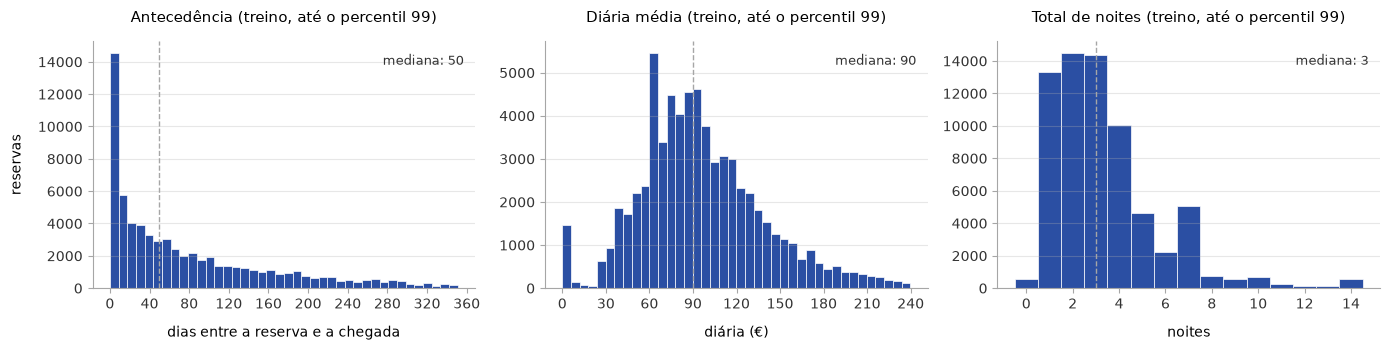

In [22]:
from matplotlib.ticker import MaxNLocator

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (coluna, titulo, rotulo) in zip(eixos, [
        ('lead_time', 'Antecedência', 'dias entre a reserva e a chegada'),
        ('adr', 'Diária média', 'diária (€)'),
        ('noites', 'Total de noites', 'noites')]):
    s = treino[coluna]
    limite = s.quantile(0.99)
    bins = np.arange(0, limite + 2) - 0.5 if coluna == 'noites' else 40
    ax.hist(s[s <= limite], bins=bins, color=CORES['principal'], edgecolor='white', linewidth=0.5)
    ax.axvline(s.median(), color=CORES['referencia'], linestyle='--', linewidth=1)
    ax.text(0.97, 0.95, f'mediana: {s.median():.0f}', transform=ax.transAxes, fontsize=9,
            color='#333333', ha='right', va='top')
    ax.set_title(f'{titulo} (treino, até o percentil 99)')
    ax.set_xlabel(rotulo)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
eixos[0].set_ylabel('reservas')
plt.tight_layout()
plt.show()

**Leitura.**

- **`lead_time` tem cauda longa.** Mediana de 50 dias, mas o percentil 99 é 351 e o máximo, 737. 6,6% das reservas são para o próprio dia. Uma reta no logito dificilmente cobre de 0 a 737 dias: confirma a ideia das faixas, a conferir na bivariada.
- **`adr` concentra-se entre 66 e 120** (p25 e p75), com mediana de 90, percentil 99 de 240 e máximo de 508. 2,1% das reservas têm diária zero, que aparece como pico à esquerda no gráfico.
- **`noites`: metade das reservas fica de 2 a 4 noites** (p25 e p75), com mediana de 3 e percentil 99 de 14. O pico em 7 é a semana fechada. Faixas de 1, 2–3, 4–7 e mais de 7 noites acompanham esse desenho.
- **Cinco contagens são quase sempre zero:** `babies` (99,0%), `days_in_waiting_list` (97,7%), `previous_bookings_not_canceled` (96,8%), `previous_cancellations` (96,2%) e `children` (92,6%). Como número, o pouco que não é zero vira cauda (até 58 reservas anteriores mantidas). Se entrarem, entram como sim ou não. `babies` sozinho quase não varia; a bivariada (seção 7.1) mostra se dá para juntar com `children`.
- **`total_of_special_requests`:** 56,3% sem pedido. Candidata a "fez pedido × não fez".
- **`adults`:** o p25 e o p75 são 2, e o máximo é 55. Como número, a cauda pesa mais que o comum. Candidata a "sozinho × acompanhado".

### 6.3 Categóricas

In [23]:
categoricas = ['hotel', 'market_segment', 'distribution_channel', 'customer_type', 'meal',
               'reserved_room_type', 'is_repeated_guest']

frequencias = pd.concat({
    c: treino[c].value_counts().rename('reservas').to_frame().assign(pct=lambda t: t['reservas'] / t['reservas'].sum())
    for c in categoricas
})
frequencias.index.names = ['variavel', 'nivel']
frequencias['abaixo_de_1pct'] = frequencias['pct'] < 0.01
frequencias.round(4)

reservas     pct  abaixo_de_1pct
variavel             nivel                                            
hotel                City Hotel          42651  0.6273           False
                     Resort Hotel        25339  0.3727           False
market_segment       Online TA           33735  0.4962           False
                     Offline TA/TO       14666  0.2157           False
                     Direct               7942  0.1168           False
                     Groups               7424  0.1092           False
                     Corporate            3575  0.0526           False
                     Complementary         521  0.0077            True
                     Aviation              127  0.0019            True
distribution_channel TA/TO               54270  0.7982           False
                     Direct               9174  0.1349           False
                     Corporate            4440  0.0653           False
                     GDS                   105  0.0015            True
                     Undefined               1  0.0000            True
customer_type        Transient           46945  0.6905           False
                     Transient-Party     17831  0.2623           False
                     Contract             2866  0.0422           False
                     Group                 348  0.0051            True
meal                 BB                  53147  0.7817           False
                     HB                   8382  0.1233           False
                     SC                   5408  0.0795           False
                     Undefined             644  0.0095            True
                     FB                    409  0.0060            True
reserved_room_type   A                   48026  0.7064           False
                     D                   11427  0.1681           False
                     E                    3744  0.0551           False
                     F                    1794  0.0264           False
                     G                    1256  0.0185           False
                     B                     900  0.0132           False
                     C                     450  0.0066            True
                     H                     387  0.0057            True
                     L                       6  0.0001            True
is_repeated_guest    0                   65673  0.9659           False
                     1                    2317  0.0341           False

In [24]:
# meses: volume por mês de chegada no treino (2015 só tem julho a dezembro)
meses = ['January', 'February', 'March', 'April', 'May', 'June',
         'July', 'August', 'September', 'October', 'November', 'December']
pd.crosstab(pd.Categorical(treino['arrival_date_month'], meses), treino['arrival_date_year'], margins=True)

arrival_date_year,2015,2016,All
row_0,,,
January,0,2050,2050
February,0,3382,3382
March,0,4229,4229
April,0,4481,4481
May,0,4745,4745
June,0,4316,4316
July,2544,4282,6826
August,3299,4792,8091
September,3905,4636,8541


**Leitura.**

- **Categorias abaixo de 1% do treino:**
  - `market_segment`: Complementary (0,8%) e Aviation (0,2%). Juntam em "Outros";
  - `customer_type`: Group (348 reservas, 0,5%). Precisa juntar com outra categoria; a bivariada mostra com qual ela se parece;
  - `meal`: Undefined (644, 0,95%) e FB (409, 0,6%). Undefined fica separado ou junta com SC (seção 4.3); FB pode juntar com HB em "com pensão";
  - `reserved_room_type`: C, H e L (L tem 6 reservas). A variável tende a sair: o código do quarto não significa nada para o público;
  - `distribution_channel`: GDS (0,15%) e uma reserva Undefined. A variável tende a sair por repetir o segmento.
- **Referências naturais (a categoria mais frequente):** City Hotel (62,7%), Online TA (49,6%), Transient (69,1%), BB (78,2%).
- **`is_repeated_guest`:** 3,4% de hóspedes que voltam. Pequeno, mas são 2.317 reservas: dá para estimar.
- **O treino não pesa os meses por igual.** 2015 só tem julho a dezembro, então esses meses aparecem em dois anos e janeiro a junho, só em 2016. O efeito de janeiro a junho é estimado com um ano só.

### 6.4 Treino × teste

In [25]:
# a distribuição das candidatas muda em 2017? (o teste só tem janeiro a agosto)
comparacao_num = pd.DataFrame({
    'mediana_treino': treino[['lead_time', 'adr', 'noites']].median(),
    'mediana_teste': teste[['lead_time', 'adr', 'noites']].median(),
})
display(comparacao_num)

# mesmos meses (janeiro a agosto) para tirar o efeito da época do ano na diária e na antecedência
treino_jan_ago = treino[treino['arrival_date_month'].isin(jan_a_ago) & (treino['arrival_date_year'] == 2016)]
display(pd.DataFrame({
    'mediana_2016_jan_ago': treino_jan_ago[['lead_time', 'adr', 'noites']].median(),
    'mediana_2017_jan_ago': teste[['lead_time', 'adr', 'noites']].median(),
}))

composicao = pd.concat({
    c: pd.DataFrame({'treino': treino[c].value_counts(normalize=True),
                     'teste': teste[c].value_counts(normalize=True)})
    for c in ['hotel', 'market_segment', 'customer_type']
}).fillna(0)
composicao['diferenca_pp'] = (composicao['teste'] - composicao['treino']) * 100
composicao.round(3)

,mediana_treino,mediana_teste
lead_time,50.0,73.0
adr,90.0,108.0
noites,3.0,3.0


,mediana_2016_jan_ago,mediana_2017_jan_ago
lead_time,54.0,73.0
adr,94.5,108.0
noites,3.0,3.0


treino  teste  diferenca_pp
hotel          City Hotel        0.627  0.648         2.041
               Resort Hotel      0.373  0.352        -2.041
market_segment Aviation          0.002  0.003         0.109
               Complementary     0.008  0.006        -0.199
               Corporate         0.053  0.038        -1.504
               Direct            0.117  0.127         0.972
               Groups            0.109  0.084        -2.517
               Offline TA/TO     0.216  0.124        -9.214
               Online TA         0.496  0.620        12.352
customer_type  Transient         0.690  0.812        12.130
               Transient-Party   0.262  0.164        -9.811
               Contract          0.042  0.018        -2.405
               Group             0.005  0.006         0.086

**Leitura.**

- **2017 reserva com mais antecedência e paga mais caro.** Nos mesmos meses (janeiro a agosto), a antecedência mediana sobe de 54 para 73 dias, e a diária mediana, de 94,5 para 108. O total de noites não muda (3).
- **O mix muda bastante:**
  - a agência online passa de 49,6% para 62,0% das reservas (+12,4 pontos), e a operadora tradicional cai 9,2 pontos;
  - o cliente avulso (Transient) passa de 69,0% para 81,2% (+12,1 pontos), e o avulso ligado a outra reserva (Transient-Party) cai 9,8 pontos.
- **O que isso muda:**
  - se a bivariada mostrar que a agência online e a antecedência longa cancelam mais, parte da alta de 2017 vem da composição. Essa parte o modelo capta, porque as variáveis estão nele; o resto aparece na calibração;
  - a diária sobe em 2017 também por preço. Se `adr` entrar como número, a mesma diária quer dizer coisas diferentes em cada ano. A conferir na bivariada se a relação entre a diária e o cancelamento é a mesma no treino e no teste.

## 7. Bivariada

**Pergunta:** como cada candidata se relaciona com o cancelamento, e em que forma ela entra no modelo?

Tudo no **treino** (2015 e 2016, no escopo). O teste só aparece quando a pergunta é se a relação se mantém em 2017.

### 7.1 Numéricas: número, faixas ou binária?

Na regressão logística, uma variável numérica tem efeito de reta no logito. O gráfico abaixo mostra o logito empírico de cada faixa contra o valor típico da faixa (a mediana): se os pontos caem numa reta, a variável entra como número; se não, vira faixas ou binária. Contínuas são cortadas em decis; contagens, por valor.

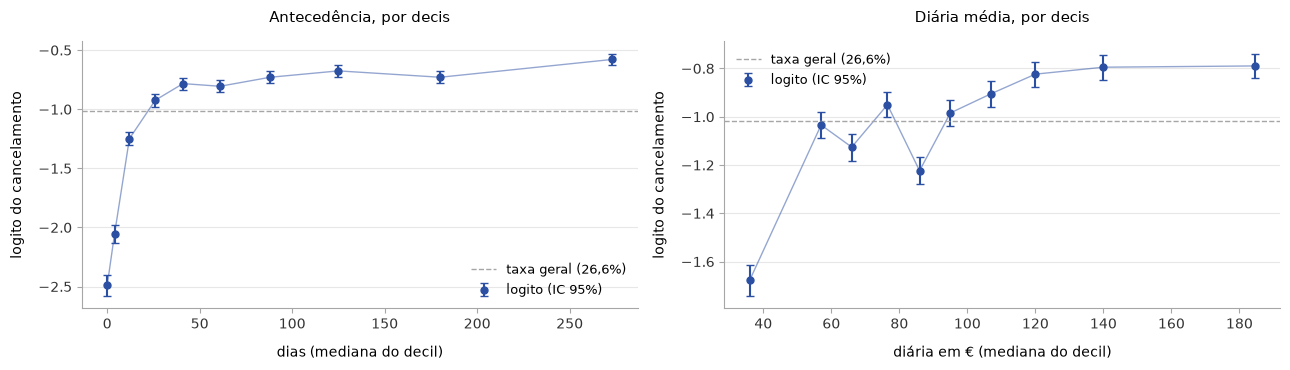

,n,taxa,logito,x
lead_time,,,,
"(-0.001, 1.0]",6907,0.076,-2.491,0.0
"(1.0, 7.0]",6857,0.114,-2.052,4.0
"(7.0, 18.0]",7086,0.223,-1.249,12.0
"(18.0, 33.0]",6512,0.284,-0.923,26.0
"(33.0, 50.0]",6670,0.314,-0.783,41.0
"(50.0, 73.0]",6797,0.309,-0.806,61.0
"(73.0, 104.0]",6874,0.325,-0.729,88.0
"(104.0, 150.0]",6784,0.337,-0.675,125.0
"(150.0, 215.0]",6753,0.325,-0.729,180.0


,n,taxa,logito,x
adr,,,,
"(-0.001, 47.0]",6822,0.157,-1.677,36.000
"(47.0, 62.0]",7096,0.262,-1.034,57.000
"(62.0, 72.0]",6680,0.245,-1.126,66.000
"(72.0, 80.75]",6940,0.279,-0.950,76.500
"(80.75, 90.0]",6776,0.227,-1.224,85.945
"(90.0, 100.0]",6724,0.272,-0.984,95.000
"(100.0, 113.0]",6557,0.288,-0.905,107.000
"(113.0, 129.0]",6807,0.305,-0.824,120.000
"(129.0, 156.6]",6811,0.311,-0.795,140.000


,n,taxa,ic_inf,ic_sup
faixa_adr,,,,
zero,1412,0.104,0.089,0.121
até 47,5410,0.171,0.162,0.182
acima de 47,61168,0.278,0.274,0.282


In [26]:
taxa_treino = treino['is_canceled'].mean()

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (coluna, titulo, rotulo) in zip(eixos, [('lead_time', 'Antecedência, por decis', 'dias (mediana do decil)'),
                                                ('adr', 'Diária média, por decis', 'diária em € (mediana do decil)')]):
    grafico_logito(logito_por_faixa(treino, coluna), titulo=titulo, rotulo_x=rotulo, taxa_geral=taxa_treino, ax=ax)
plt.tight_layout()
plt.show()

colunas = ['n', 'taxa', 'logito', 'x']
display(logito_por_faixa(treino, 'lead_time')[colunas].round(3))
display(logito_por_faixa(treino, 'adr')[colunas].round(3))

# o primeiro decil da diária inclui as diárias zero (seção 4.3)
taxa_por_nivel(treino.assign(faixa_adr=pd.cut(treino['adr'], [-1, 0, 47, np.inf], labels=['zero', 'até 47', 'acima de 47'])),
               'faixa_adr')[['n', 'taxa', 'ic_inf', 'ic_sup']].round(3)

**Leitura.**

- **A antecedência não é linear no logito.** O cancelamento sobe rápido até um mês, de 7,6% (no mesmo dia ou no seguinte) para 28,4% (19 a 33 dias), e depois quase para: entre 30,9% e 35,9% de 34 a 737 dias. Uma reta não cobre os dois trechos. **Entra em faixas.**
- **A diária também não é linear.** O primeiro decil (até 47) cancela 15,7%, puxado pelas diárias zero (10,4%). Entre 47 e 100, a taxa oscila de 22,7% a 27,9%, sem escada; acima de 113, fica perto de 31%. **Vira faixas.** Os cortes ficam para depois de controlar hotel e temporada: a diária muda com os dois, e parte desse desenho pode vir deles.

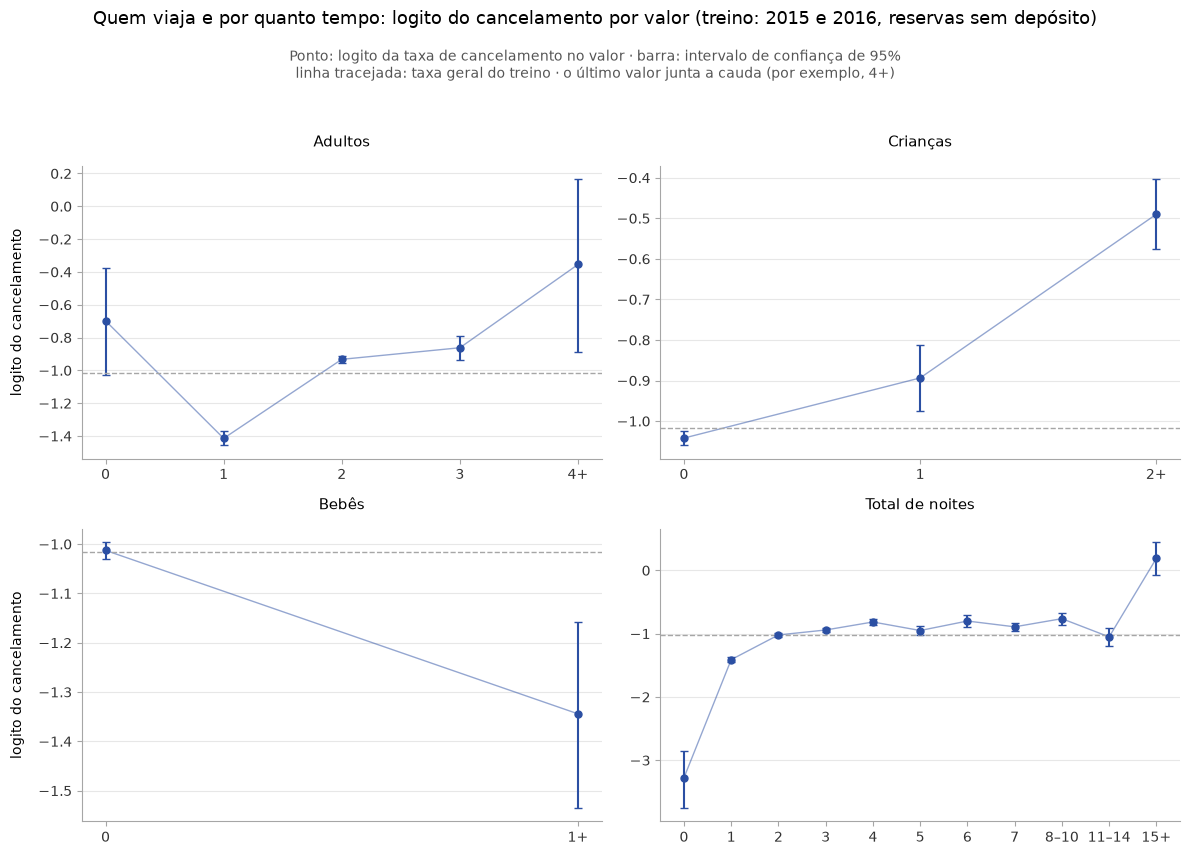

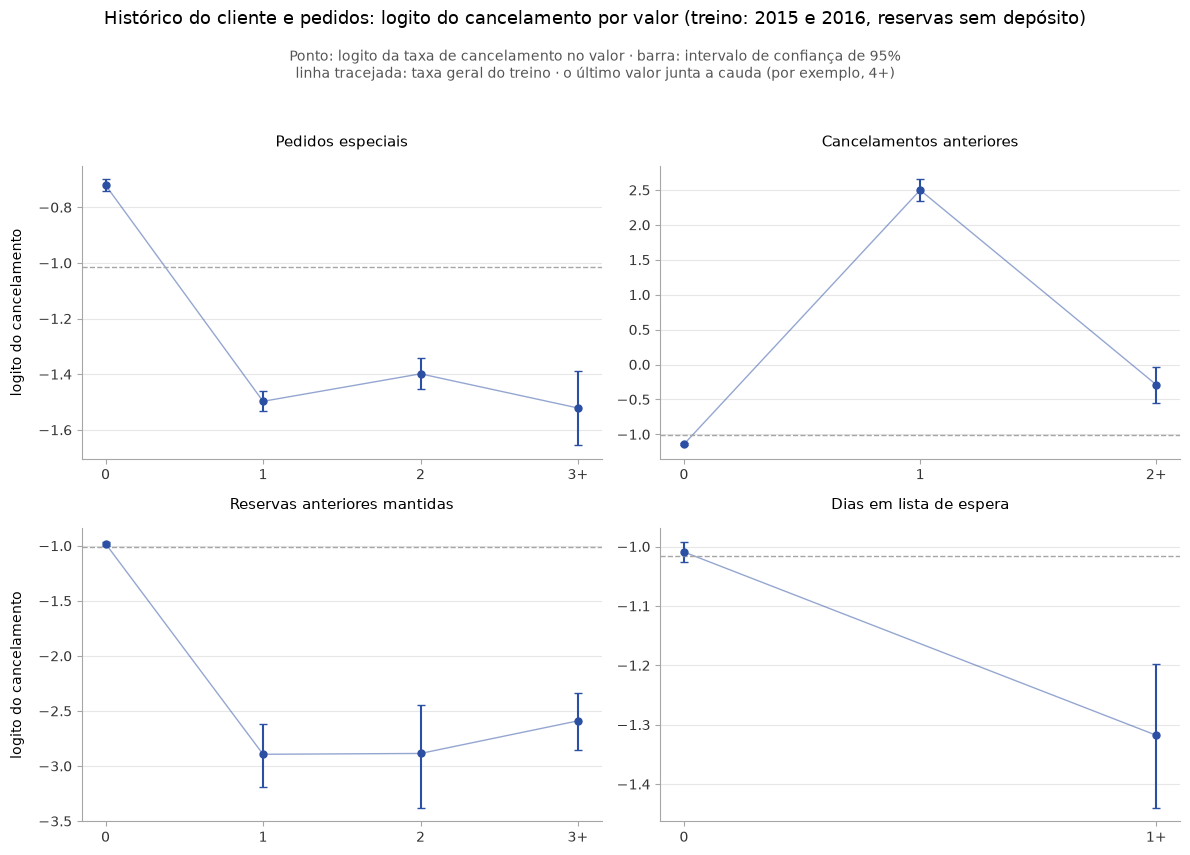

n   taxa  ic_inf  ic_sup
adults                         0        160  0.331   0.263   0.407
                               1      13720  0.196   0.189   0.202
                               2      50507  0.282   0.278   0.286
                               3       3547  0.297   0.282   0.312
                               4+        56  0.411   0.292   0.541
children                       0      62954  0.261   0.257   0.264
                               1       2859  0.290   0.274   0.307
                               2+      2177  0.380   0.360   0.400
babies                         0      67331  0.266   0.263   0.270
                               1+       659  0.206   0.177   0.239
noites                         0        535  0.036   0.023   0.055
                               1      13318  0.196   0.189   0.203
                               2      14477  0.265   0.258   0.272
                               3      14350  0.280   0.273   0.288
                               4      10025  0.307   0.298   0.316
                               5       4657  0.279   0.266   0.292
                               6       2250  0.310   0.291   0.329
                               7       5055  0.291   0.278   0.303
                               8–10    2036  0.318   0.298   0.338
                               11–14   1055  0.259   0.233   0.286
                               15+      232  0.547   0.483   0.610
total_of_special_requests      0      38295  0.327   0.323   0.332
                               1      20433  0.183   0.178   0.188
                               2       7793  0.198   0.189   0.207
                               3+      1469  0.179   0.160   0.199
previous_cancellations         0      65434  0.242   0.239   0.245
                               1       2322  0.924   0.913   0.934
                               2+       234  0.427   0.366   0.491
previous_bookings_not_canceled 0      65819  0.273   0.269   0.276
                               1        942  0.052   0.040   0.068
                               2        349  0.052   0.033   0.080
                               3+       880  0.069   0.054   0.088
days_in_waiting_list           0      66426  0.267   0.264   0.271
                               1+      1564  0.211   0.191   0.232

In [27]:
# contagens: o último nível junta a cauda (por exemplo, 4+ = 4 ou mais adultos)
grupos = {
    'Quem viaja e por quanto tempo': [
        ('adults', [-1, 0, 1, 2, 3, np.inf], ['0', '1', '2', '3', '4+'], 'Adultos'),
        ('children', [-1, 0, 1, np.inf], ['0', '1', '2+'], 'Crianças'),
        ('babies', [-1, 0, np.inf], ['0', '1+'], 'Bebês'),
        ('noites', [-1, 0, 1, 2, 3, 4, 5, 6, 7, 10, 14, np.inf],
         ['0', '1', '2', '3', '4', '5', '6', '7', '8–10', '11–14', '15+'], 'Total de noites'),
    ],
    'Histórico do cliente e pedidos': [
        ('total_of_special_requests', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3+'], 'Pedidos especiais'),
        ('previous_cancellations', [-1, 0, 1, np.inf], ['0', '1', '2+'], 'Cancelamentos anteriores'),
        ('previous_bookings_not_canceled', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3+'], 'Reservas anteriores mantidas'),
        ('days_in_waiting_list', [-1, 0, np.inf], ['0', '1+'], 'Dias em lista de espera'),
    ],
}

tabelas = {}
for tema, contagens in grupos.items():
    fig, eixos = plt.subplots(2, 2, figsize=(12, 8.5))
    for ax, (coluna, limites, rotulos, titulo) in zip(eixos.flat, contagens):
        tabelas[coluna] = logito_por_faixa(treino, coluna, limites=limites)
        tabelas[coluna]['x'] = range(len(rotulos))   # níveis igualmente espaçados; a cauda fica no último
        tabelas[coluna].index = rotulos
        grafico_logito(tabelas[coluna], titulo=titulo, taxa_geral=taxa_treino, ax=ax)
        ax.set_xticks(range(len(rotulos)), rotulos)
        ax.get_legend().remove()
        ax.set_ylabel('')
    for ax in eixos[:, 0]:
        ax.set_ylabel('logito do cancelamento')
    fig.suptitle(f'{tema}: logito do cancelamento por valor (treino: 2015 e 2016, reservas sem depósito)',
                 fontsize=13, y=1.0)
    fig.text(0.5, 0.955, 'Ponto: logito da taxa de cancelamento no valor · barra: intervalo de confiança de 95%\n'
             'linha tracejada: taxa geral do treino · o último valor junta a cauda (por exemplo, 4+)',
             ha='center', va='top', fontsize=10, color='#555555')
    plt.tight_layout(rect=(0, 0, 1, 0.91))
    plt.show()

pd.concat({c: t[['n', 'taxa', 'ic_inf', 'ic_sup']] for c, t in tabelas.items()}).round(3)


**Leitura.**

- **`adults`: o nível 1 se separa.** Um adulto cancela 19,6%; dois, 28,2%; três, 29,7%, com intervalos que quase se tocam. Os extremos têm poucas reservas e intervalos largos: 0 adulto (160 reservas, 33,1%) e 4 ou mais (56, 41,1%). **Binária: sozinho (1 adulto) × acompanhado** (os demais, incluindo os 160 sem adulto).
- **`children`: escada.** Sem criança, 26,1%; uma, 29,0%; duas ou mais, 38,0%. **Binária, com criança × sem**, ou três níveis se o modelo mostrar que a diferença entre uma e duas compensa.
- **`babies` vai no sentido oposto.** Com bebê, 20,6% (IC de 17,7% a 23,9%), contra 26,6% sem. Juntar com `children` misturaria efeitos contrários. São 659 reservas (1% do treino). **Sai.**
- **`noites`: zero noites é outro comportamento.** 3,6% de cancelamento (535 reservas), contra 19,6% com uma noite; de 2 a 14 noites, a taxa fica entre 25,9% e 31,8%. 15 noites ou mais cancelam 54,7%, mas são só 232. **Entra em faixas** (abaixo).
- **`total_of_special_requests`: o que importa é fazer algum pedido.** Sem pedido, 32,7%; com 1, 2 ou 3 ou mais, entre 17,9% e 19,8%. **Binária: fez pedido × não fez**, se o momento do score permitir.
- **`previous_bookings_not_canceled`: o mesmo desenho.** Nunca veio, 27,3%; já veio uma ou mais vezes, entre 5,2% e 6,9%. **Binária: já veio × nunca veio.**
- **`days_in_waiting_list`:** quem esperou cancela 21,1%, contra 26,7%. São 2,3% das reservas: pouco ganho para uma variável a mais. **Sai.**
- **`previous_cancellations` não segue escada nenhuma:** uma vez, 92,4%; duas ou mais, 42,7%. Investigado abaixo.

In [28]:
# cancelamentos anteriores: quem são as reservas com exatamente 1?
treino_pc = treino.assign(cancelou_antes=treino['previous_cancellations'].clip(upper=2),
                          tem_gemea=tem_gemea[treino.index])
display(treino_pc.groupby('cancelou_antes').agg(
    reservas=('is_canceled', 'size'),
    taxa=('is_canceled', 'mean'),
    pct_2015=('arrival_date_year', lambda s: (s == 2015).mean()),
    antecedencia_mediana=('lead_time', 'median'),
    pct_com_gemea=('tem_gemea', 'mean'),
    pct_hospede_repetido=('is_repeated_guest', 'mean'),
).rename(index={2: '2 ou mais'}))

# a relação se mantém em 2017?
pd.DataFrame({
    'taxa_treino': treino.groupby(treino['previous_cancellations'].clip(upper=2))['is_canceled'].mean(),
    'taxa_teste': teste.groupby(teste['previous_cancellations'].clip(upper=2))['is_canceled'].mean(),
    'n_teste': teste.groupby(teste['previous_cancellations'].clip(upper=2)).size(),
}).rename(index={2: '2 ou mais'}).round(3)

,reservas,taxa,pct_2015,antecedencia_mediana,pct_com_gemea,pct_hospede_repetido
cancelou_antes,,,,,,
0,65434,0.241908,0.250206,49.0,0.251887,0.025904
1,2322,0.924203,0.798450,199.0,0.651163,0.197244
2 ou mais,234,0.427350,0.282051,8.0,0.252137,0.700855


,taxa_treino,taxa_teste,n_teste
previous_cancellations,,,
0,0.242,0.319,36189
1,0.924,0.175,194
2 ou mais,0.427,0.169,83


**Leitura.**

- **As reservas com exatamente um cancelamento anterior não são clientes que costumam cancelar.** 79,8% são de 2015 (contra 25,0% das reservas sem cancelamento anterior), têm antecedência mediana de 199 dias e 65,1% têm gêmea. É o perfil dos blocos de quartos da seção 4.2, concentrados no início da base.
- **Em 2017, a relação se inverte.** No teste, quem tem um cancelamento anterior cancela 17,5%, contra 31,9% de quem não tem. No treino eram 92,4%. Uma variável que muda de sentido entre os períodos ensinaria ao modelo uma regra que não vale no futuro.
- **Explicação provável:** em 2015, a contagem parece registrar os outros quartos do mesmo bloco cancelado, e não o histórico do cliente. Não dá para confirmar sem o sistema do hotel.
- **Proposta: sai.** O histórico do cliente continua representado por "já veio × nunca veio".

In [29]:
# faixas propostas para a antecedência e o total de noites
faixas_lead = pd.cut(treino['lead_time'], [-1, 7, 30, 90, 180, np.inf],
                     labels=['até 7', '8–30', '31–90', '91–180', 'mais de 180'])
faixas_noites = pd.cut(treino['noites'], [-1, 1, 3, 7, np.inf], labels=['até 1', '2–3', '4–7', 'mais de 7'])

display(taxa_por_nivel(treino.assign(faixa_lead=faixas_lead), 'faixa_lead')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']].round(3))
taxa_por_nivel(treino.assign(faixa_noites=faixas_noites), 'faixa_noites')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']].round(3)

,n,pct_base,taxa,ic_inf,ic_sup
faixa_lead,,,,,
até 7,13764,0.202,0.095,0.090,0.100
8–30,12261,0.180,0.248,0.241,0.256
31–90,18721,0.275,0.308,0.301,0.314
91–180,13177,0.194,0.334,0.326,0.342
mais de 180,10067,0.148,0.354,0.345,0.363


,n,pct_base,taxa,ic_inf,ic_sup
faixa_noites,,,,,
até 1,13853,0.204,0.190,0.183,0.197
2–3,28827,0.424,0.273,0.268,0.278
4–7,21987,0.323,0.297,0.291,0.303
mais de 7,3323,0.049,0.315,0.300,0.331


**Leitura.**

- **Antecedência em cinco faixas:** até 7 dias, 9,5%; 8–30, 24,8%; 31–90, 30,8%; 91–180, 33,4%; mais de 180, 35,4%. As faixas acompanham a curva, e os intervalos de faixas vizinhas não se sobrepõem. A primeira junta o mesmo dia (7,6%) e de 2 a 7 dias (11,4%), que ficam próximos. **Proposta: estas faixas, com 31–90 como referência** (a maior, 27,5% do treino).
- **Noites em quatro faixas:** até 1, 19,0%; 2–3, 27,3%; 4–7, 29,7%; mais de 7, 31,5%. Juntar as 535 reservas de zero noites com as de uma noite quase não mexe na faixa (de 19,6% para 19,0%) e evita uma categoria de 0,8% do treino. As duas últimas faixas têm intervalos que se tocam (29,1%–30,3% e 30,0%–33,1%): se o modelo não as separar, juntam em "4 ou mais". **Referência: 2–3** (42,4% do treino).

### 7.2 Categóricas: força e agrupamentos

O V de Cramér ordena as candidatas pela força da associação com o cancelamento (de 0 a 1). Com muitos níveis, o V tende a sair maior só por isso: a comparação vale melhor entre variáveis com poucos níveis.

In [30]:
treino = treino.assign(
    segmento=treino['market_segment'].replace({'Complementary': 'Outros', 'Aviation': 'Outros', 'Undefined': 'Outros'}),
    tem_agencia=treino['agent'].notna(),
    tem_empresa=treino['company'].notna(),
)

candidatas = ['hotel', 'segmento', 'distribution_channel', 'customer_type', 'meal', 'reserved_room_type',
              'is_repeated_guest', 'arrival_date_month', 'tem_agencia', 'tem_empresa', 'agent', 'company']
pd.DataFrame({
    'niveis': [treino[c].nunique() for c in candidatas],
    'V_cramer': [v_cramer(treino, c) for c in candidatas],
}, index=candidatas).sort_values('V_cramer', ascending=False).round(3)

,niveis,V_cramer
company,289,0.404
agent,275,0.283
segmento,6,0.195
distribution_channel,5,0.129
tem_agencia,2,0.113
tem_empresa,2,0.087
arrival_date_month,12,0.081
meal,5,0.072
hotel,2,0.070
customer_type,4,0.048


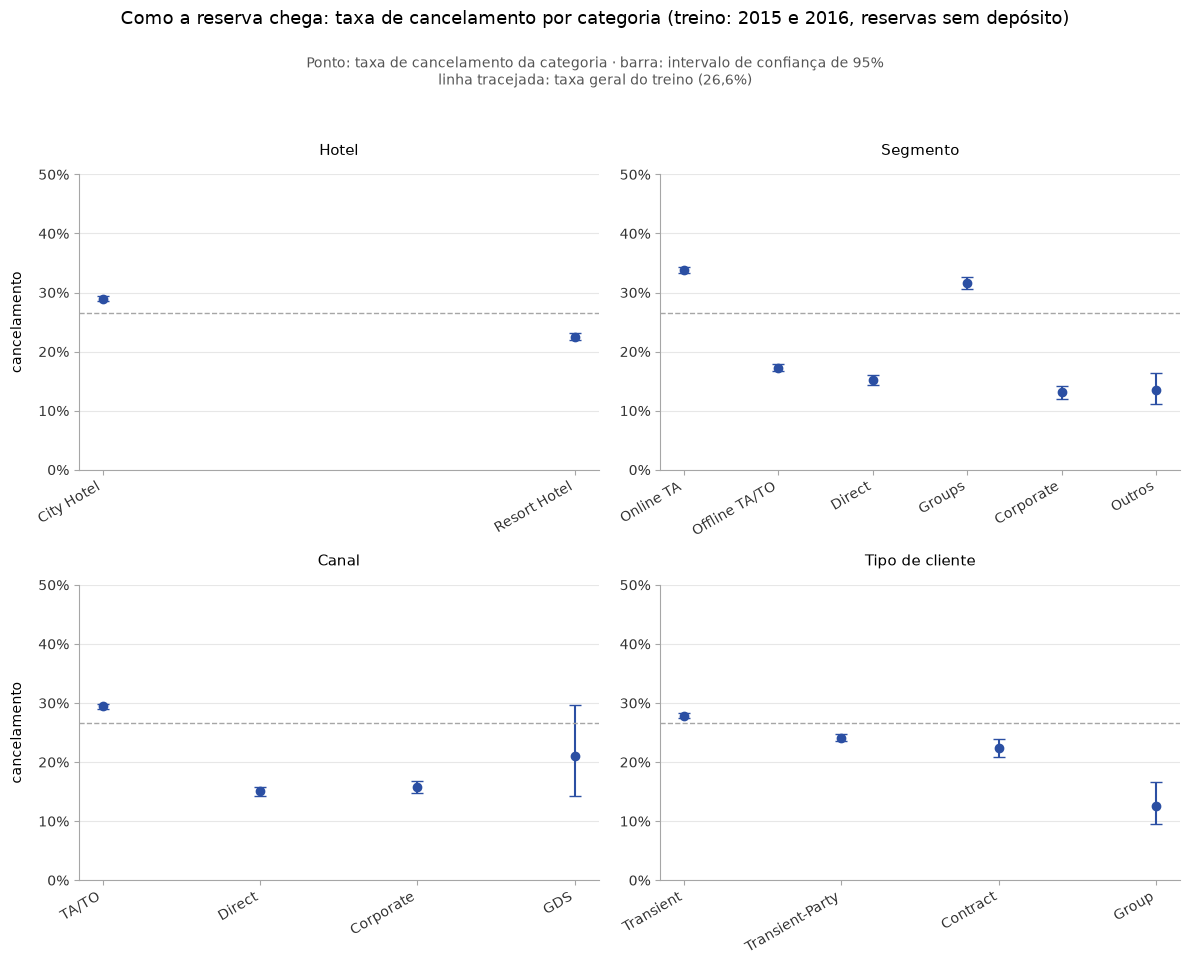

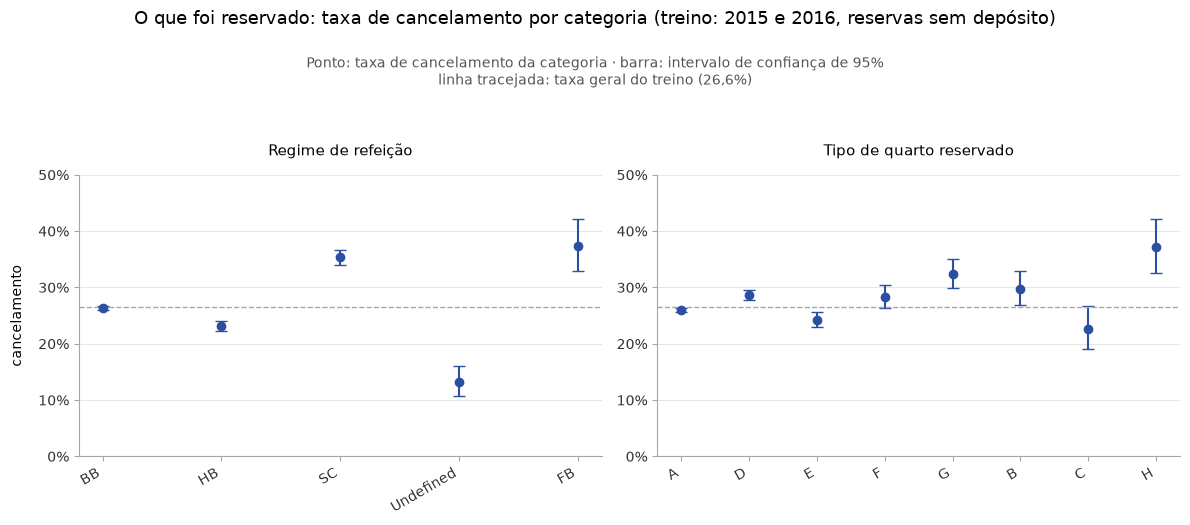

n   taxa  ic_inf  ic_sup
hotel                City Hotel       42651  0.290   0.286   0.294
                     Resort Hotel     25339  0.225   0.220   0.231
segmento             Corporate         3575  0.131   0.120   0.142
                     Direct            7942  0.152   0.144   0.160
                     Groups            7424  0.316   0.305   0.327
                     Offline TA/TO    14666  0.173   0.167   0.179
                     Online TA        33735  0.339   0.334   0.344
                     Outros             648  0.136   0.112   0.164
distribution_channel Corporate         4440  0.157   0.147   0.168
                     Direct            9174  0.150   0.143   0.158
                     GDS                105  0.210   0.143   0.297
                     TA/TO            54270  0.294   0.291   0.298
                     Undefined            1  0.000   0.000   0.793
customer_type        Contract          2866  0.224   0.209   0.239
                     Group              348  0.126   0.096   0.165
                     Transient        46945  0.279   0.275   0.283
                     Transient-Party  17831  0.241   0.235   0.248
meal                 BB               53147  0.263   0.260   0.267
                     FB                 409  0.374   0.329   0.422
                     HB                8382  0.231   0.222   0.240
                     SC                5408  0.353   0.341   0.366
                     Undefined          644  0.132   0.108   0.160
reserved_room_type   A                48026  0.259   0.256   0.263
                     B                  900  0.298   0.269   0.328
                     C                  450  0.227   0.190   0.268
                     D                11427  0.287   0.278   0.295
                     E                 3744  0.243   0.229   0.257
                     F                 1794  0.283   0.263   0.304
                     G                 1256  0.324   0.299   0.350
                     H                  387  0.372   0.325   0.421
                     L                    6  0.333   0.097   0.700
is_repeated_guest    0                65673  0.269   0.265   0.272
                     1                 2317  0.183   0.168   0.200

In [31]:
# níveis com menos de 30 reservas ficam só na tabela (intervalo largo demais para o gráfico)
temas = {
    'Como a reserva chega': [('hotel', 'Hotel'), ('segmento', 'Segmento'),
                             ('distribution_channel', 'Canal'), ('customer_type', 'Tipo de cliente')],
    'O que foi reservado': [('meal', 'Regime de refeição'), ('reserved_room_type', 'Tipo de quarto reservado')],
}
legenda = (f'Ponto: taxa de cancelamento da categoria · barra: intervalo de confiança de 95%\n'
           f'linha tracejada: taxa geral do treino ({taxa_treino:.1%})'.replace('.', ','))

for tema, variaveis in temas.items():
    linhas = (len(variaveis) + 1) // 2
    fig, eixos = plt.subplots(linhas, 2, figsize=(12, 4.4 * linhas + 0.8), squeeze=False)
    for ax, (coluna, titulo) in zip(eixos.flat, variaveis):
        tabela = taxa_por_nivel(treino, coluna).sort_values('n', ascending=False).query('n >= 30')
        grafico_taxa_por_nivel(tabela, taxa_geral=taxa_treino, titulo=titulo, ax=ax)
        ax.set_ylim(0, 0.5)   # mesma escala em todos, para comparar a força entre variáveis
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
        ax.get_legend().remove()
        ax.set_ylabel('')
    for ax in eixos[:, 0]:
        ax.set_ylabel('cancelamento')
    topo = 1 - 0.85 / fig.get_figheight()   # espaço fixo para o título e a legenda
    fig.suptitle(f'{tema}: taxa de cancelamento por categoria (treino: 2015 e 2016, reservas sem depósito)',
                 fontsize=13, y=1.0)
    fig.text(0.5, 1 - 0.45 / fig.get_figheight(), legenda, ha='center', va='top', fontsize=10, color='#555555')
    plt.tight_layout(rect=(0, 0, 1, topo))
    plt.show()

pd.concat({c: taxa_por_nivel(treino, c)[['n', 'taxa', 'ic_inf', 'ic_sup']]
           for c in ['hotel', 'segmento', 'distribution_channel', 'customer_type', 'meal', 'reserved_room_type',
                     'is_repeated_guest']}).round(3)


**Leitura.**

- **O segmento é a categórica mais forte** (V de 0,195). Agência online cancela 33,9% e grupos, 31,6%; operadora tradicional, 17,3%; direto, 15,2%; corporativo, 13,1%. **Entra, com a agência online como referência.**
- **`agent` e `company` têm V alto (0,283 e 0,404), mas com 275 e 289 códigos.** Boa parte disso vem do número de níveis. Investigadas abaixo.
- **O canal repete o segmento com menos detalhe** (V de 0,129). TA/TO (29,4%) mistura a agência online (33,9%) e a operadora tradicional (17,3%). **Sai**; a redundância é conferida na seção 8.
- **Hotel:** urbano 29,0%, resort 22,5% (V de 0,070). **Entra**: é o primeiro corte do negócio.
- **Tipo de cliente:** avulso 27,9%, avulso ligado a outra reserva 24,1%, contrato 22,4% e grupo 12,6% (V de 0,048). Fraco. O nível Group é investigado abaixo.
- **Tipo de quarto:** taxas de 22,7% a 37,2%, sem ordem, e o código não significa nada para o público (V de 0,039). **Sai.**
- **Hóspede que volta:** 18,3% contra 26,9% (V de 0,035). Parecido com "já veio × nunca veio" (seção 7.1); a redundância é conferida na seção 8.

In [32]:
# meal: Undefined e SC são a mesma coisa? Onde cada um aparece
display(pd.crosstab(treino['meal'], treino['hotel'], margins=True, margins_name='total'))
taxa_por_nivel(treino, ['hotel', 'meal'])[['n', 'taxa', 'ic_inf', 'ic_sup']].round(3)

hotel,City Hotel,Resort Hotel,total
meal,,,
BB,33626,19521,53147
FB,41,368,409
HB,3616,4766,8382
SC,5368,40,5408
Undefined,0,644,644
total,42651,25339,67990


n   taxa  ic_inf  ic_sup
hotel        meal                                   
City Hotel   BB         33626  0.286   0.281   0.291
             FB            41  0.854   0.716   0.931
             HB          3616  0.224   0.210   0.238
             SC          5368  0.356   0.343   0.369
Resort Hotel BB         19521  0.225   0.219   0.230
             FB           368  0.321   0.275   0.370
             HB          4766  0.236   0.224   0.249
             SC            40  0.025   0.004   0.129
             Undefined    644  0.132   0.108   0.160

**Leitura.**

- **Cada hotel registra "sem refeição" de um jeito.** Undefined só aparece no resort (644 reservas, nenhuma no urbano); SC aparece quase só no urbano (5.368, contra 40 no resort).
- **E os dois vão em sentidos opostos.** No urbano, SC cancela 35,6%, contra 28,6% do café da manhã (BB). No resort, Undefined cancela 13,2%, contra 22,5% do BB. Juntar SC e Undefined em "sem refeição" mistura um efeito para cima com um para baixo.
- **Pensão completa (FB):** 85,4% no urbano, mas são só 41 reservas; 32,1% no resort (368). Meia pensão (HB) fica perto de 23% nos dois hotéis.
- **Proposta: `meal` vai para teste com quatro níveis**: BB (referência), com pensão (HB e FB), SC e Undefined. Undefined fica separado mesmo sendo pequeno (0,9% do treino), porque não se parece com nenhum outro nível. A variável é fraca (V de 0,072): se não melhorar o modelo, sai.

In [33]:
# customer_type = Group (348 reservas): de que segmentos vêm, e com quem se parece?
pd.crosstab(treino['customer_type'], treino['segmento'], normalize='index').round(2)

segmento,Corporate,Direct,Groups,Offline TA/TO,Online TA,Outros
customer_type,,,,,,
Contract,0.01,0.00,0.06,0.41,0.52,0.00
Group,0.04,0.23,0.01,0.38,0.33,0.01
Transient,0.05,0.15,0.01,0.14,0.63,0.01
Transient-Party,0.07,0.04,0.38,0.37,0.13,0.00


**Leitura.**

- **Group (348 reservas, 12,6% de cancelamento) não se parece com nenhum outro tipo de cliente.** O mais próximo é contrato (22,4%). Vem de operadoras (38%), agência online (33%) e reservas diretas (23%): não é o mesmo que o segmento Groups.
- **O avulso ligado a outra reserva (Transient-Party) é 38% do segmento Groups**: o tipo de cliente repete parte do segmento.
- **Proposta:** se o tipo de cliente entrar, Group junta com contrato em "contrato ou grupo" (3.214 reservas), as duas formas de reserva acertadas com o hotel. A seção 8 confere se a variável acrescenta algo ao segmento.

In [34]:
# mês de chegada: o padrão se repete nos dois anos do treino?
por_mes_ano = treino.pivot_table(index='arrival_date_month', columns='arrival_date_year',
                                 values='is_canceled', aggfunc=['mean', 'size']).reindex(meses)
display(por_mes_ano.round(3))

temporada = treino['arrival_date_month'].map({'July': 'jul–ago', 'August': 'jul–ago',
                                              'April': 'abr–jun', 'May': 'abr–jun', 'June': 'abr–jun'}).fillna('set–mar')
taxa_por_nivel(treino.assign(temporada=temporada), ['temporada', 'arrival_date_year'])[['n', 'taxa', 'ic_inf', 'ic_sup']].round(3)

mean           size        
arrival_date_year    2015   2016    2015    2016
arrival_date_month                              
January               NaN  0.175     NaN  2050.0
February              NaN  0.247     NaN  3382.0
March                 NaN  0.228     NaN  4229.0
April                 NaN  0.260     NaN  4481.0
May                   NaN  0.258     NaN  4745.0
June                  NaN  0.260     NaN  4316.0
July                0.404  0.285  2544.0  4282.0
August              0.307  0.327  3299.0  4792.0
September           0.228  0.274  3905.0  4636.0
October             0.170  0.322  3868.0  5411.0
November            0.177  0.255  2248.0  3755.0
December            0.201  0.323  2428.0  3619.0

n   taxa  ic_inf  ic_sup
temporada arrival_date_year                              
abr–jun   2016               13542  0.259   0.252   0.267
jul–ago   2015                5843  0.350   0.338   0.362
          2016                9074  0.307   0.298   0.317
set–mar   2015               12449  0.196   0.189   0.203
          2016               27082  0.269   0.264   0.275

**Leitura.**

- **O padrão por mês não se repete nos dois anos.** Julho cancelou 40,4% em 2015 e 28,5% em 2016; outubro, 17,0% e 32,2%; dezembro, 20,1% e 32,3%. Com 12 meses como categorias, o modelo aprenderia oscilações de um ano só.
- **Só julho e agosto ficam acima nos dois anos:** 35,0% em 2015 e 30,7% em 2016. Os outros meses mudam de nível de um ano para o outro.
- **Abril a junho não se separa de setembro a março.** Em 2016, o único ano com os dois períodos, cancelam 25,9% e 26,9%, com intervalos que se tocam. As três temporadas do dicionário viram, na prática, duas.
- **Proposta: alta temporada (julho e agosto) × resto do ano.** A diferença de 2015 para 2016 em setembro a março (19,6% para 26,9%) é a mesma tendência de alta vista na seção 3, e não um efeito da época do ano.

In [35]:
# agência e empresa: o vazio diz algo além do segmento?
display(taxa_por_nivel(treino, ['segmento', 'tem_agencia'])[['n', 'taxa']].round(3))
display(taxa_por_nivel(treino, ['segmento', 'tem_empresa'])[['n', 'taxa']].round(3))

# as maiores agências: o código separa reservas de risco diferente?
maiores = treino['agent'].value_counts().head(8).index
print('Agências no treino:', treino['agent'].nunique(),
      f"| as 8 maiores somam {treino['agent'].isin(maiores).mean():.1%} das reservas")
(taxa_por_nivel(treino[treino['agent'].isin(maiores)], ['agent', 'segmento'])[['n', 'taxa']]
     .query('n >= 100').round(3))

n   taxa
segmento      tem_agencia              
Corporate     False         3023  0.125
              True           552  0.165
Direct        False         4201  0.126
              True          3741  0.181
Groups        False         1537  0.230
              True          5887  0.338
Offline TA/TO False          148  0.257
              True         14518  0.172
Online TA     False          227  0.070
              True         33508  0.341
Outros        False          566  0.133
              True            82  0.159

n   taxa
segmento      tem_empresa              
Corporate     False          649  0.154
              True          2926  0.126
Direct        False         7810  0.153
              True           132  0.106
Groups        False         6799  0.340
              True           625  0.048
Offline TA/TO False        14638  0.173
              True            28  0.071
Online TA     False        33666  0.339
              True            69  0.043
Outros        False          315  0.121
              True           333  0.150

Agências no treino: 275 | as 8 maiores somam 58.2% das reservas


,,n,taxa
agent,segmento,,
1.0,Groups,3074,0.390
6.0,Offline TA/TO,1984,0.138
7.0,Online TA,2123,0.138
9.0,Online TA,18656,0.386
14.0,Direct,1967,0.195
28.0,Offline TA/TO,1124,0.045
240.0,Online TA,8922,0.358
250.0,Direct,1687,0.164


**Leitura.**

- **`tem_agencia` repete o segmento.** Na agência online e na operadora, quase todas as reservas têm agência; as sem agência são poucas (227 e 148). Onde há volume nos dois lados (direto, corporativo e grupos), ter agência soma de 4 a 11 pontos, mas o segmento já separa a maior parte. **Sai.**
- **`tem_empresa` separa dentro do segmento.** Nos grupos, a reserva paga por empresa cancela 4,8% (625 reservas), contra 34,0% sem empresa. No corporativo, a diferença é pequena (12,6% contra 15,4%). São 4.113 reservas com empresa (6,0% do treino). **Proposta: testar "paga por empresa" como binária.** A empresa é conhecida na reserva, e a leitura para o negócio é direta.
- **O código da agência separa reservas do mesmo segmento.** Na agência online, a agência 9 cancela 38,6% e a 7, 13,8%; na operadora, a 6 cancela 13,8% e a 28, 4,5%. Mas são 275 códigos anônimos, e as 8 maiores somam 58,2% das reservas. **Sai do modelo:** dummies por código não se explicam para a diretoria. **Próximo passo para o negócio:** com o nome real das agências, a taxa por agência vira uma lista de parceiros a acompanhar.